# Finding a Maximum Margin Classifier Using a Linear SVM

## About This Project

In this project, you will find a maximum margin classifier by implementing a linear support vector machine (SVM). You will generate a linearly separable dataset, write functions to build a linear SVM, and then visualize the decision boundary. You will also have the chance to add data points to a visualization of your linear SVM to see how it responds to new data.

### Evaluation

**This project must be successfully completed and submitted in order to receive credit for this course. Your score on this project will be included in your final grade calculation.**
    
You are expected to write code where you see `# YOUR CODE HERE` within the cells of this notebook. Not all cells will be graded; code input cells followed by cells marked with `# Auto-graded test cell` will be graded. Upon submitting your work, the code you write at these designated positions will be assessed using an "auto-grader" that will run all test cells to assess your code. You will receive feedback from the auto-grader that will identify any errors in your code. Use this feedback to improve your code if you need to resubmit. Be sure not to change the names of any provided functions, classes, or variables within the existing code cells, as this will interfere with the auto-grader. Also, remember to execute all code cells sequentially, not just those you’ve edited, to ensure your code runs properly.
    
You can resubmit your work as many times as necessary before the submission deadline. If you experience difficulty or have questions about this exercise, use the Q&A discussion board to engage with your peers or seek assistance from the instructor.

Before starting your work, please review [eCornell's policy regarding plagiarism](https://s3.amazonaws.com/ecornell/global/eCornellPlagiarismPolicy.pdf) (the presentation of someone else's work as your own without source credit).

### Submit Code for Auto-Grader Feedback

Once you have completed your work on this notebook, you will submit your code for auto-grader review. Follow these steps:

1. **Save your notebook.**

2. **Mark as Completed** — In the blue menu bar along the top of this code exercise window, you’ll see a menu item called **Education**. In the **Education** menu, click **Mark as Completed** to submit your code for auto-grader/instructor review. This process will take a moment and a progress bar will show you the status of your submission.

3. **Review your results** — Once your work is marked as complete, the results of the auto-grader will automatically be presented in a new tab within the code exercise window. You can click on the assessment name in this feedback window to see more details regarding specific feedback/errors in your code submission.

4. **Repeat, if necessary** — The Jupyter notebook will always remain accessible in the first tabbed window of the exercise. To reattempt the work, you will first need to click **Mark as Uncompleted** in the **Education** menu and then proceed to make edits to the notebook. Once you are ready to resubmit, follow steps one through three. You can repeat this procedure as many times as necessary.

You can also download a copy of this notebook in multiple formats using the **Save and Export Notebook As** option in the **File** menu above.

## Getting Started

### Python Initialization

Please run the following code to initialize your Python kernel. You should be running a version of Python 3.x.

In [1]:
import numpy as np
from numpy.matlib import repmat
from scipy.stats import linregress
import time

# Interactive matplotlib plots
%matplotlib ipympl
import matplotlib.pyplot as plt

import sys
sys.path.append("/home/codio/workspace/.modules")
from helper import *

print("Python version:", sys.version.split(" ")[0])

Python version: 3.12.5


### Generate and Visualize Data

Let's generate some linearly seperable data and visualize it in order to get a sense of what you will be working with. Run the cell below to generate and visualize the data.

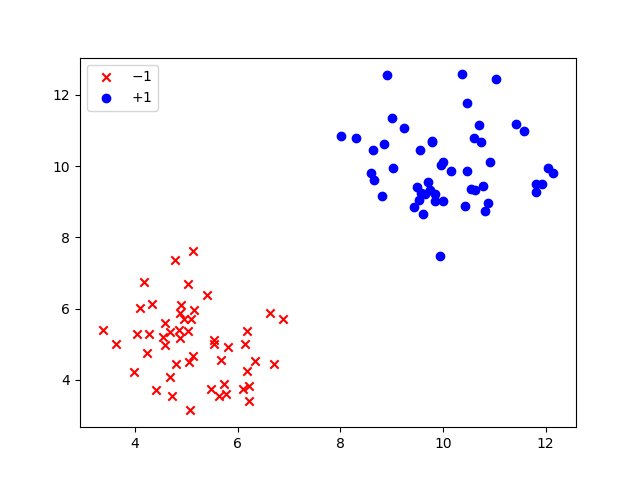

In [2]:
xTr, yTr = generate_data()
visualize_2D(xTr, yTr)

## Linear SVM

Recall that the unconstrained loss function formulation for linear SVM is 

$$
\underbrace{\mathbf{w}^\top\mathbf{w}}_{\text{L2-regularizer}} 
+ C\sum_{i=1}^n\underbrace{\max\left[1-y_i\left(\mathbf{w}^\top\mathbf{x}_i+b\right),0\right]}_{\text{hinge loss}}
$$

However, the hinge loss is not differentiable when $1-y_{i}\left(\mathbf{w}^\top\mathbf{x}_i+b\right)=0$. So, we are going to use the squared hinge loss instead:

$$
\mathcal{L}(\mathbf{w},b) 
= \underbrace{\mathbf{w}^\top\mathbf{w}}_{\text{L2-regularizer}} 
+ C\sum_{i=1}^n\underbrace{\max\left[1-y_i\left(\mathbf{w}^\top\mathbf{x}_i+b\right),0\right]^2}_{\text{squared hinge loss}}
$$

### Part One: Loss Function [Graded]

Firstly, implement the function **`loss`**, which takes in training data `xTr` ($n \times d$) and labels `yTr` with `yTr[i]` either `-1` or `1` and calculates $\mathcal{L}(\mathbf{w}, b)$ using the **squared hinge loss** for the classifier parameterized by `w, b` with hyperparameter `C`.

You might find the function [`np.maximum(a, b)`](https://numpy.org/doc/stable/reference/generated/numpy.maximum.html) useful. It returns the element-wise maximum between each corresponding element of arrays `a` and `b`.

In [15]:
def loss(w, b, xTr, yTr, C):
    """
    Calculates the squared hinge loss plus the L2-regularizer,
    as defined in the equation above.

    Input:
        w: d-dimensional weight vector
        b: Bias term (a scalar)
        xTr: nxd data matrix (each row is an input vector)
        yTr: n-dimensional vector (each entry is a label)
        C: Constant that controls the tradeoff between
           the L2-regularizer and hinge-loss (a scalar)

    Output:
        loss_val: Squared loss plus the L2-regularizer for
                  the classifier on xTr and yTr (a scalar)
    """
    loss_val = 0.0

    # YOUR CODE HERE
    scores = xTr @ w + b
    margins = yTr * scores
    hinge_losses = np.maximum(0,1 - margins)**2
    loss_val = np.dot(w,w) + C * np.sum(hinge_losses)
    # END OF YOUR CODE
    return loss_val

Run the next cell to check your implementation of `loss`.

In [16]:
# Generate data for testing your function loss() 
xTr_test, yTr_test = generate_data()
n, d = xTr_test.shape


def loss_test1():
    """
    Check that function loss() returns a scalar
    """
    w = np.random.rand(d)
    b = np.random.rand(1)
    loss_val = loss(w, b, xTr_test, yTr_test, 10)
    return np.isscalar(loss_val)


def loss_test2():
    """
    Check that loss() returns a non-negative scalar
    """
    w = np.random.rand(d)
    b = np.random.rand(1)
    loss_val = loss(w, b, xTr_test, yTr_test, 10)
    return loss_val >= 0


def loss_test3():
    """
    Check that L2-regularizer is implemented correctly
    """
    w = np.random.rand(d)
    b = np.random.rand(1)
    loss_val = loss(w, b, xTr_test, yTr_test, 0)
    loss_val_grader = loss_grader(w, b, xTr_test, yTr_test, 0)
    return np.linalg.norm(loss_val - loss_val_grader) < 1e-5


def loss_test4():
    """
    Check that squared hinge loss is implementedand and not standard hinge loss.
    Note: loss_grader_wrong is the wrong implementation of standard hinge loss,
    so the results should NOT match.
    """
    w = np.random.randn(d)
    b = np.random.rand(1)
    loss_val = loss(w, b, xTr_test, yTr_test, 1)
    badloss = loss_grader_wrong(w, b, xTr_test, yTr_test, 1)
    return not (np.linalg.norm(loss_val - badloss) < 1e-5)


def loss_test5():
    """
    Check that squared hinge loss is implemented correctly
    """
    w = np.random.randn(d)
    b = np.random.rand(1)
    loss_val = loss(w, b, xTr_test, yTr_test, 10)
    loss_val_grader = loss_grader(w, b, xTr_test, yTr_test, 10)
    return np.linalg.norm(loss_val - loss_val_grader) < 1e-5


def loss_test6():
    """
    Check that function loss() is implemented correctly
    """
    w = np.random.randn(d)
    b = np.random.rand(1)
    loss_val = loss(w, b, xTr_test, yTr_test, 100)
    loss_val_grader = loss_grader(w, b, xTr_test, yTr_test, 100)
    return np.linalg.norm(loss_val - loss_val_grader) < 1e-5


runtest(loss_test1, "loss_test1")
runtest(loss_test2, "loss_test2")
runtest(loss_test3, "loss_test3")
runtest(loss_test4, "loss_test4")
runtest(loss_test5, "loss_test5")
runtest(loss_test6, "loss_test6")

Running Test: loss_test1 ... ✔ Passed!
Running Test: loss_test2 ... ✔ Passed!
Running Test: loss_test3 ... ✔ Passed!
Running Test: loss_test4 ... ✔ Passed!
Running Test: loss_test5 ... ✔ Passed!
Running Test: loss_test6 ... ✔ Passed!


Skip over the auto-graded test cells below (see [Evaluation](#Evaluation) for details).

In [ ]:
# Auto-graded test cell worth one point (loss_test1)

In [ ]:
# Auto-graded test cell worth one point (loss_test2)

In [ ]:
# Auto-graded test cell worth one point (loss_test3)

In [ ]:
# Auto-graded test cell worth one point (loss_test4)

In [ ]:
# Auto-graded test cell worth one point (loss_test5)

In [ ]:
# Auto-graded test cell worth one point (loss_test5)

### Part Two: Gradient of Loss Function [Graded]

Now, implement **`grad`**, which takes in the same arguments as the `loss` function but returns gradients of $\mathcal{L}$ (with squared hinge loss) with respect to $\mathbf{w}$ and $b$.

Here are the equations for your reference:

$$
\begin{aligned}
\frac{\partial\mathcal{L}}{\partial\mathbf{w}}
&= 2 \mathbf{w} 
- 2C\sum_{i=1}^{n} y_i\mathbf{x}_i\max\left[1-y_{i}\left(\mathbf{w}^\top\mathbf{x}_i+b\right),0\right] \\
\frac{\partial\mathcal{L}}{\partial b}
&= -2C\sum_{i=1}^{n} y_i\max\left[1-y_{i}\left(\mathbf{w}^\top\mathbf{x}_i+b\right),0\right]
\end{aligned}
$$

You might be able to reuse some of the code from your implementation of `loss` above.

In [38]:
def grad(w, b, xTr, yTr, C):
    """
    Calculates the gradients of the loss function,
    as given by the expressions above.

    Input:
        w: d-dimensional weight vector
        b: Bias term (a scalar)
        xTr: nxd data matrix (each row is an input vector)
        yTr: n-dimensional vector (each entry is a label)
        C: Constant that controls the tradeoff between
           the L2-regularizer and hinge loss (a scalar)

    OUTPUTS:
        wgrad, bgrad
        wgrad: d-dimensional gradient of the loss with
               respect to the weight vector w
        bgrad: Gradient of the loss with respect to
               the bias term b (a scalar)
    """
    n, d = xTr.shape

    wgrad = np.zeros(d)
    bgrad = np.zeros(1)

    # YOUR CODE HERE
    wgrad += 2 * w
    for i in range(n):
        margin = yTr[i] * (np.dot(w, xTr[i]) + b)
        hinge = np.maximum(1-margin,0)

        wgrad -= 2*C*yTr[i] * xTr[i] * hinge
        bgrad -= 2 * C * yTr[i] * hinge
    bgrad = bgrad.item()
    # END OF YOUR CODE

    return wgrad, bgrad

Run the next cell to check your implementation of `grad`.

In [39]:
# Generate test data for testing grad()
xTr_test, yTr_test = generate_data()
n, d = xTr_test.shape


def grad_test1():
    """
    Checks whether grad() returns a tuple of length 2
    """
    w = np.random.rand(d)
    b = np.random.rand(1)
    out = grad(w, b, xTr_test, yTr_test, 10)
    return type(out) == tuple and len(out) == 2


def grad_test2():
    """
    Checks the dimension of gradients
    """
    w = np.random.rand(d)
    b = np.random.rand(1)
    wgrad, bgrad = grad(w, b, xTr_test, yTr_test, 10)
    return len(wgrad) == d and np.isscalar(bgrad)


def grad_test3():
    """
    Checks the gradient of the L2-regularizer
    """
    w = np.random.rand(d)
    b = np.random.rand(1)
    wgrad, bgrad = grad(w, b, xTr_test, yTr_test, 0)
    wgrad_grader, bgrad_grader = grad_grader(w, b, xTr_test, yTr_test, 0)
    return (np.linalg.norm(wgrad - wgrad_grader) < 1e-5) and (
        np.linalg.norm(bgrad - bgrad_grader) < 1e-5
    )


def grad_test4():
    """
    Checks the gradient of the squared hinge loss
    """
    w = np.zeros(d)
    b = np.random.rand(1)
    wgrad, bgrad = grad(w, b, xTr_test, yTr_test, 1)
    wgrad_grader, bgrad_grader = grad_grader(w, b, xTr_test, yTr_test, 1)
    return (np.linalg.norm(wgrad - wgrad_grader) < 1e-5) and (
        np.linalg.norm(bgrad - bgrad_grader) < 1e-5
    )


def grad_test5():
    """
    Checks the gradient of the loss function
    """
    w = np.random.rand(d)
    b = np.random.rand(1)
    wgrad, bgrad = grad(w, b, xTr_test, yTr_test, 10)
    wgrad_grader, bgrad_grader = grad_grader(w, b, xTr_test, yTr_test, 10)
    return (np.linalg.norm(wgrad - wgrad_grader) < 1e-5) and (
        np.linalg.norm(bgrad - bgrad_grader) < 1e-5
    )


runtest(grad_test1, "grad_test1")
runtest(grad_test2, "grad_test2")
runtest(grad_test3, "grad_test3")
runtest(grad_test4, "grad_test4")
runtest(grad_test5, "grad_test5")

Running Test: grad_test1 ... ✔ Passed!
Running Test: grad_test2 ... ✔ Passed!
Running Test: grad_test3 ... ✔ Passed!
Running Test: grad_test4 ... ✔ Passed!
Running Test: grad_test5 ... ✔ Passed!


Skip over the auto-graded test cells below (see [Evaluation](#Evaluation) for details).

In [ ]:
# Auto-graded test cell worth one point (grad_test1)

In [ ]:
# Auto-graded test cell worth one point (grad_test2)

In [ ]:
# Auto-graded test cell worth one point (grad_test3)

In [ ]:
# Auto-graded test cell worth one point (grad_test4)

In [ ]:
# Auto-graded test cell worth one point (grad_test5)

### Obtain the Linear SVM

By calling the following minimization routine implemented for you in the cell below, you will obtain your linear SVM. Since the objective also includes the L2-regularizer, the output loss that you would see would not be 0. But you can subtract off the regularizer term $\mathbf{w}^\top \mathbf{w}$ to check that your squared hinge loss is indeed close to 0.

In [40]:
w, b, final_loss = minimize(objective=loss, grad=grad, xTr=xTr, yTr=yTr, C=1000)
print(f"The final loss of your model is {100 * final_loss:.2f}%.")
print(
    "The final squared hinge loss of your model is",
    f"{100 * (final_loss - np.dot(w, w)):.2f}%.",
)

The final loss of your model is 32.40%.
The final squared hinge loss of your model is 0.00%.


### Visualize the Decision Boundary

Now, let's visualize the decision boundary on our linearly separable dataset. Since the dataset is linearly separable,  you should obtain $0\%$ training error with sufficiently large values of $C$ (e.g., $C>1000$).

Training Error: 0.00%


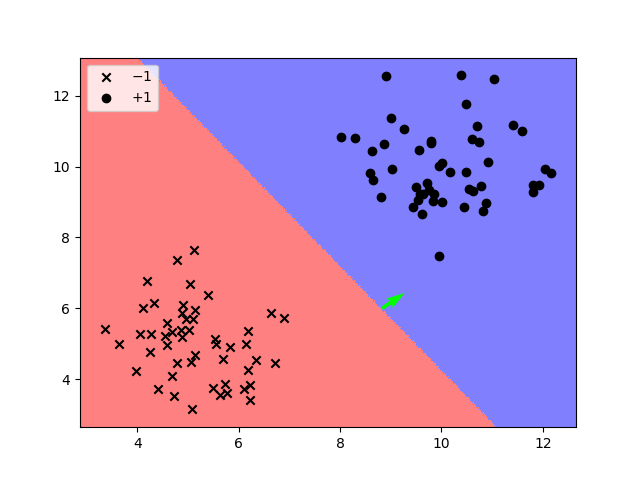

In [41]:
# Calculate training error
err = np.mean(np.sign(xTr.dot(w) + b) != yTr)
print(f"Training Error: {100 * err:.2f}%")

# Visualize classifier and decision boundary
visualize_classfier(xTr, yTr, w, b)

### Interactive Demo

Running the code below will create an interactive window where you can click to add new data points to see how your linear SVM will respond. There may be a significant delay between clicks.

In the interactive plot below:
1. Click to add a positive point
2. Shift+click to add a negative point


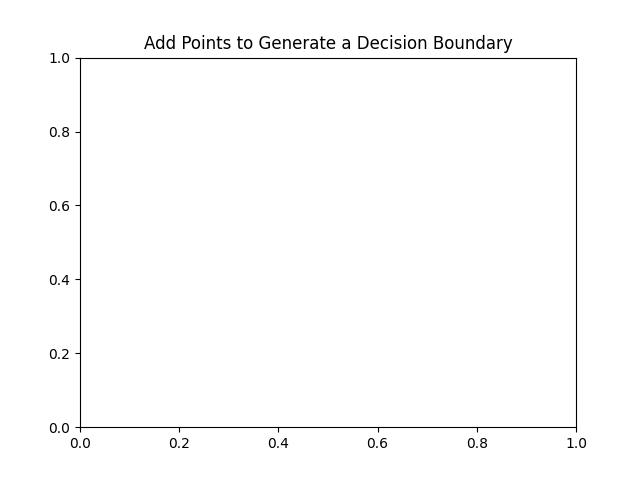

In [42]:
# Initialize lists to store click data
Xdata = []
ldata = []

fig = plt.figure()
details = {
    "w": None,
    "b": None,
    "stepsize": 1,
    "ax": fig.add_subplot(111),
    "line": None,
}


def updateboundary(Xdata, ldata):
    global details
    w_pre, b_pre, _ = minimize(
        objective=loss,
        grad=grad,
        xTr=np.concatenate(Xdata),
        yTr=np.array(ldata),
        C=1000,
    )
    details["w"] = np.array(w_pre).reshape(-1)
    details["b"] = b_pre
    details["stepsize"] += 1


def updatescreen():
    global details
    b = details["b"]
    w = details["w"]
    q = -b / (w**2).sum() * w
    if details["line"] is None:
        (details["line"],) = details["ax"].plot(
            [q[0] - w[1], q[0] + w[1]], [q[1] + w[0], q[1] - w[0]], "k--"
        )
    else:
        details["line"].set_ydata([q[1] + w[0], q[1] - w[0]])
        details["line"].set_xdata([q[0] - w[1], q[0] + w[1]])


def generate_onclick(Xdata, ldata):
    global details

    def onclick(event):
        if event.key == "shift":  # Add negative point
            details["ax"].plot(event.xdata, event.ydata, "rx")
            label = -1
        else:  # Add positive point
            details["ax"].plot(event.xdata, event.ydata, "bo")
            label = 1
        pos = np.array([[event.xdata, event.ydata]])
        ldata.append(label)
        Xdata.append(pos)
        updateboundary(Xdata, ldata)
        updatescreen()

    return onclick


plt.xlim(0, 1)
plt.ylim(0, 1)
plt.title("Add Points to Generate a Decision Boundary")
print("In the interactive plot below:")
print("1. Click to add a positive point")
print("2. Shift+click to add a negative point")
cid = fig.canvas.mpl_connect("button_press_event", generate_onclick(Xdata, ldata))
plt.show()

### Scikit-Learn Implementation

Scikit-learn also provides a [Linear SVM Classifier](https://scikit-learn.org/stable/modules/generated/sklearn.svm.LinearSVC.html) implementation that is easy to use.

Training error: 0.00%


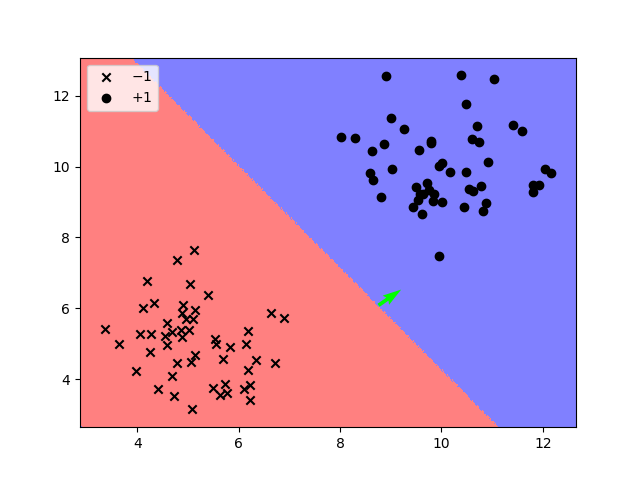

In [43]:
from sklearn.svm import LinearSVC

clf = LinearSVC(
    penalty="l2",
    loss="squared_hinge",
    C=1000,
    max_iter=1000,
    random_state=0,
)
clf.fit(xTr, yTr)

# Calculate training error
err = np.mean(clf.predict(xTr) != yTr)
print(f"Training error: {100 * err:.2f}%")

# Visualize classifier and decision boundary
visualize_classfier(xTr, yTr, clf.coef_, clf.intercept_)